# Histogram recovery, end to end

One code, five parts, no randomness anywhere.

1. **Encode** --- one message, every step shown, $p = 3$, $m = 3$, $K = 3$.
2. **Bundle** --- add 1 codeword, then 2, then 3, ... up to the theoretical bound plus 10.
3. **Decode** --- unbundle, worked by hand for $t = 1, 2, 3$ with the histograms printed
   at every step, then run until it breaks.
4. **The graph** --- how many went in versus how many came out, and where they part.
5. **Past the bound** --- raise the multiplicity $d$ and decode $t = 14$ anyway.

The code: $N = p^m = 27$ symbols, hypervectors of dimension $p^{2m} = 729$, and
$N^K = 19{,}683$ possible messages. The paper's worst-case guarantee --- how many distinct
codewords can *always* be pulled back out of a bundle, whatever was bundled --- is

$$u_{\max} = \left\lfloor \frac{N-1}{K-1} \right\rfloor = \left\lfloor \frac{26}{2} \right\rfloor = 13$$

so Part 2 bundles up to $t = 23$.

That is a guarantee, not a wall. Part 3 does hit a wall at exactly 13, but only because
it decodes with multiplicity $d = 1$; Part 5 shows $d = 4$ recovering all of $t = 14$.

In [1]:
import time

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import sage.all__sagemath_modules as _sage_bootstrap    # must precede sage.coding
from sage.coding.grs_code import GeneralizedReedSolomonCode
from sage.coding.guruswami_sudan.gs_decoder import GRSGuruswamiSudanDecoder
from sage.coding.guruswami_sudan.interpolation import gs_interpolation_linalg
from sage.rings.finite_rings.finite_field_constructor import GF

%matplotlib inline
np.set_printoptions(precision=3, suppress=True, linewidth=200)


def load_notebook_defs(path):
    """exec another notebook's code cells, skipping figures and magics."""
    import ast, contextlib, io, json

    def draws(src):
        try:
            tree = ast.parse(src)
        except SyntaxError:
            return False
        return any(isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute)
                   and n.func.attr in ("show", "savefig") for n in ast.walk(tree))

    nb = json.loads(open(path).read())
    ns = {}
    for cell in nb["cells"]:
        if cell["cell_type"] != "code":
            continue
        src = "".join(cell["source"])
        if draws(src):
            continue
        src = "\n".join(("# " + ln) if ln.lstrip()[:1] in ("%", "!") else ln
                        for ln in src.split("\n"))
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(compile(src, path, "exec"), ns)
        except Exception:
            pass
    return ns


enc = load_notebook_defs("encode_m.ipynb")

p, m, K = 3, 3, 3
q = N = p ** m
DIM = p ** (2 * m)
vec, ADD, MUL = tab = enc["gf_tables"](p, m)

F = GF(q, "a", modulus=enc["find_irreducible"](p, m))
gen = F.gen()
points = [sum(int(c) * gen ** k for k, c in enumerate(vec[i])) for i in range(N)]
FROM_SAGE = {points[i]: i for i in range(N)}
CODE = GeneralizedReedSolomonCode(points, K)
ROOT_FINDER = GRSGuruswamiSudanDecoder(
    CODE, tau=1, interpolation_alg="LinearAlgebra").rootfinding_algorithm()

U_MAX = (N - 1) // (K - 1)
T_LIMIT = U_MAX + 10

print(f"p = {p}, m = {m}, K = {K}")
print(f"  N    = p^m  = {N}      symbols, and codeword length")
print(f"  dim  = p^2m = {DIM}     hypervector length")
print(f"  size = N^K  = {N ** K}   possible messages")
print(f"  u_max       = {U_MAX}      theoretical limit on unbundling")
print(f"  Part 2 will bundle up to t = {T_LIMIT}")

p = 3, m = 3, K = 3
  N    = p^m  = 27      symbols, and codeword length
  dim  = p^2m = 729     hypervector length
  size = N^K  = 19683   possible messages
  u_max       = 13      theoretical limit on unbundling
  Part 2 will bundle up to t = 23


# Part 1 --- Encode

The paper's eq. (1), one layer at a time. A message of $K = 3$ symbols becomes a
hypervector of $729$ complex numbers.

In [2]:
MESSAGE = [2, 1, 5]

print(f"STEP 0 -- the message: K = {K} symbols from F_({p}^{m})")
print(f"   u = {MESSAGE}")
print(f"   each symbol is really {m} digits base {p}:")
for i, s in enumerate(MESSAGE):
    print(f"      u[{i}] = {s:>2}  ->  digits {list(vec[s])}"
          f"   ({s} = {' + '.join(f'{c}*{p}^{k}' for k, c in enumerate(vec[s]) if c)})")

STEP 0 -- the message: K = 3 symbols from F_(3^3)
   u = [2, 1, 5]
   each symbol is really 3 digits base 3:
      u[0] =  2  ->  digits [2, 0, 0]   (2 = 2*3^0)
      u[1] =  1  ->  digits [1, 0, 0]   (1 = 1*3^0)
      u[2] =  5  ->  digits [2, 1, 0]   (5 = 2*3^0 + 1*3^1)


In [3]:
print(f"STEP 1 -- Reed-Solomon: read the message as polynomial coefficients")
terms = " + ".join(f"{c}" if k == 0 else f"{c}*x^{k}"
                   for k, c in enumerate(MESSAGE) if c)
print(f"   f(x) = {terms}")
print(f"   evaluate f at all {N} field elements (field arithmetic, not integer):\n")

codeword = list(enc["reed_solomon_encode"](MESSAGE, p, m, tab))
print(f"   {'x':>4} {'f(x)':>6}      {'x':>4} {'f(x)':>6}      {'x':>4} {'f(x)':>6}")
for r in range(9):
    cells = [f"   {j:>4} {codeword[j]:>6}" for j in (r, r + 9, r + 18)]
    print("   ".join(cells))
print(f"\n   codeword c = {codeword}")
print(f"   length {len(codeword)} = N, each entry a symbol of F_({p}^{m})")

STEP 1 -- Reed-Solomon: read the message as polynomial coefficients
   f(x) = 2 + 1*x^1 + 5*x^2
   evaluate f at all 27 field elements (field arithmetic, not integer):

      x   f(x)         x   f(x)         x   f(x)
      0      2         9      2        18     11
      1      5        10      3        19     13
      2      3        11      5        20     13
      3      4        12      7        21     10
      4     19        13     23        22      6
      5     14        14     16        23     18
      6      7        15      4        24     10
      7     16        16     14        25     18
      8     23        17     19        26      6

   codeword c = [2, 5, 3, 4, 19, 14, 7, 16, 23, 2, 3, 5, 7, 23, 16, 4, 14, 19, 11, 13, 13, 10, 6, 18, 10, 18, 6]
   length 27 = N, each entry a symbol of F_(3^3)


In [4]:
print(f"STEP 2 -- Hadamard: replace each symbol c_j by column c_j of the Hadamard table")
L = enc["hadamard_exponents"](p, m, tab)
print(f"   the exponent table L is {L.shape[0]}x{L.shape[1]};  L[b,a] = <digits(a), digits(b)> mod {p}")
print(f"   picking out the columns named by the codeword gives a {N}x{N} grid of exponents:\n")
grid = L[:, codeword]
print(grid)
print(f"\n   column j of this grid is f_Had(c_j).  Column 0 is for c_0 = {codeword[0]}.")

STEP 2 -- Hadamard: replace each symbol c_j by column c_j of the Hadamard table
   the exponent table L is 27x27;  L[b,a] = <digits(a), digits(b)> mod 3
   picking out the columns named by the codeword gives a 27x27 grid of exponents:

[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [2 2 0 1 1 2 1 1 2 2 0 2 1 2 1 1 2 1 2 1 1 1 0 0 1 0 0]
 [1 1 0 2 2 1 2 2 1 1 0 1 2 1 2 2 1 2 1 2 2 2 0 0 2 0 0]
 [0 1 1 1 0 1 2 2 1 0 1 1 2 1 2 1 1 0 0 1 1 0 2 0 0 0 2]
 [2 0 1 2 1 0 0 0 0 2 1 0 0 0 0 2 0 1 2 2 2 1 2 0 1 0 2]
 [1 2 1 0 2 2 1 1 2 1 1 2 1 2 1 0 2 2 1 0 0 2 2 0 2 0 2]
 [0 2 2 2 0 2 1 1 2 0 2 2 1 2 1 2 2 0 0 2 2 0 1 0 0 0 1]
 [2 1 2 0 1 1 2 2 1 2 2 1 2 1 2 0 1 1 2 0 0 1 1 0 1 0 1]
 [1 0 2 1 2 0 0 0 0 1 2 0 0 0 0 1 0 2 1 1 1 2 1 0 2 0 1]
 [0 0 0 0 2 1 0 1 2 0 0 0 0 2 1 0 1 2 1 1 1 1 0 2 1 2 0]
 [2 2 0 1 0 0 1 2 1 2 0 2 1 1 2 1 0 0 0 2 2 2 0 2 2 2 0]
 [1 1 0 2 1 2 2 0 0 1 0 1 2 0 0 2 2 1 2 0 0 0 0 2 0 2 0]
 [0 1 1 1 2 2 2 0 0 0 1 1 2 0 0 1 2 2 1 2 2 1 2 2 1 2 2]
 [2 0 1 2 0 1 0 1 2 2 1

In [5]:
print(f"STEP 3 -- phi: send each exponent k to the point at angle 2*pi*k/{p} on the circle")
print(f"   p = {p}, so there are only {p} possible entries:")
for k in range(p):
    z = enc["phi"](k, p)
    print(f"      exponent {k} -> {z:+.3f}   (angle {360*k//p:>3} degrees)")

H = enc["hadamard_matrix"](p, m, tab)
hv = enc["histo_encode"](MESSAGE, p, m, tab)
print(f"\n   applying phi to the whole grid and reading it down each column, left to")
print(f"   right, gives the hypervector. First 18 of {DIM} entries:")
print(f"   {np.round(hv[:18], 3)}")

assert np.allclose(hv.reshape(N, N), H[:, codeword].T)
assert np.allclose(np.abs(hv), 1.0)
print(f"\n   dim = {hv.shape[0]} = p^2m")
print(f"   |entry| = 1 everywhere: {np.allclose(np.abs(hv), 1.0)}   (all on the unit circle)")
print(f"   norm = {np.linalg.norm(hv):.1f} = sqrt(dim) -- true of EVERY codeword")

STEP 3 -- phi: send each exponent k to the point at angle 2*pi*k/3 on the circle
   p = 3, so there are only 3 possible entries:
      exponent 0 -> +1.000+0.000j   (angle   0 degrees)
      exponent 1 -> -0.500+0.866j   (angle 120 degrees)
      exponent 2 -> -0.500-0.866j   (angle 240 degrees)

   applying phi to the whole grid and reading it down each column, left to
   right, gives the hypervector. First 18 of 729 entries:
   [ 1. +0.j    -0.5-0.866j -0.5+0.866j  1. +0.j    -0.5-0.866j -0.5+0.866j  1. +0.j    -0.5-0.866j -0.5+0.866j
  1. +0.j    -0.5-0.866j -0.5+0.866j  1. +0.j    -0.5-0.866j -0.5+0.866j  1. +0.j    -0.5-0.866j -0.5+0.866j]

   dim = 729 = p^2m
   |entry| = 1 everywhere: True   (all on the unit circle)
   norm = 27.0 = sqrt(dim) -- true of EVERY codeword


# Part 2 --- Bundle

Bundling is addition: lay the hypervectors on top of each other and add, entry by entry.

No randomness. A fixed list of messages, and bundle `t` of them for
$t = 1, 2, 3, \ldots, 23$ --- each bundle contains the previous one.

In [6]:
def nth_message(i):
    """The i-th message in a fixed order. All three slots vary, so these are
    generic codewords rather than (say) a family of constants."""
    return [(i + 1) % q, (2 * i + 1) % q, (3 * i + 2) % q]


MESSAGES = [nth_message(i) for i in range(T_LIMIT)]
assert len({tuple(u) for u in MESSAGES}) == T_LIMIT, "must be distinct"
CODEWORDS = [list(enc["reed_solomon_encode"](u, p, m, tab)) for u in MESSAGES]
HVS = [enc["histo_encode"](u, p, m, tab) for u in MESSAGES]

print(f"the fixed list, first 6 of {T_LIMIT}:")
print(f"   {'i':>3} {'message':>14}   codeword (first 10 of 27)")
for i in range(6):
    print(f"   {i:>3} {str(MESSAGES[i]):>14}   {CODEWORDS[i][:10]}")

print(f"\nbundling is addition. For t = 3, the first 6 entries:")
for i in range(3):
    print(f"   hv of message {str(MESSAGES[i]):<14} {np.round(HVS[i][:6], 2)}")
print(f"   {'sum':<28} {np.round(sum(HVS[:3])[:6], 2)}")
print(f"\n   |entry| of one codeword : all 1.0")
print(f"   |entry| of the t=3 bundle: "
      f"{np.abs(sum(HVS[:3])).min():.1f} .. {np.abs(sum(HVS[:3])).max():.1f}"
      f"   <- left the unit circle, so the bundle is NOT a codeword")

the fixed list, first 6 of 23:
     i        message   codeword (first 10 of 27)
     0      [1, 1, 2]   [1, 1, 2, 22, 25, 20, 25, 22, 20, 5]
     1      [2, 3, 5]   [2, 7, 1, 10, 0, 24, 19, 3, 12, 1]
     2      [3, 5, 8]   [3, 4, 6, 19, 5, 10, 7, 23, 13, 19]
     3     [4, 7, 11]   [4, 10, 17, 21, 22, 12, 15, 2, 14, 12]
     4     [5, 9, 14]   [5, 25, 7, 20, 26, 9, 1, 11, 16, 25]
     5    [6, 11, 17]   [6, 22, 3, 2, 19, 4, 16, 1, 17, 16]

bundling is addition. For t = 3, the first 6 entries:
   hv of message [1, 1, 2]      [ 1. +0.j   -0.5+0.87j -0.5-0.87j  1. +0.j   -0.5+0.87j -0.5-0.87j]
   hv of message [2, 3, 5]      [ 1. +0.j   -0.5-0.87j -0.5+0.87j  1. +0.j   -0.5-0.87j -0.5+0.87j]
   hv of message [3, 5, 8]      [ 1. +0.j    1. +0.j    1. +0.j   -0.5+0.87j -0.5+0.87j -0.5+0.87j]
   sum                          [ 3. +0.j   -0. +0.j   -0. +0.j    1.5+0.87j -1.5+0.87j -1.5+0.87j]

   |entry| of one codeword : all 1.0
   |entry| of the t=3 bundle: 0.0 .. 3.0   <- left the unit ci

In [7]:
print(f"bundles of t = 1 .. {T_LIMIT}, each containing the one before:\n")
print(f"   {'t':>3} {'|entry| range':>16} {'norm':>8} {'sqrt(t*dim)':>12}")
BUNDLES = []
for t in range(1, T_LIMIT + 1):
    b = sum(HVS[:t])
    BUNDLES.append(b)
    if t <= 6 or t in (10, U_MAX, U_MAX + 1, T_LIMIT):
        print(f"   {t:>3} {f'{np.abs(b).min():.1f} .. {np.abs(b).max():.1f}':>16} "
              f"{np.linalg.norm(b):>8.1f} {np.sqrt(t * DIM):>12.1f}")
print(f"\n   every bundle is still {DIM} numbers -- that is the point of a VSA:")
print(f"   the representation does not grow when you add more objects.")
print(f"   the norm grows like sqrt(t), which is why each item's share shrinks.")

bundles of t = 1 .. 23, each containing the one before:

     t    |entry| range     norm  sqrt(t*dim)
     1       1.0 .. 1.0     27.0         27.0
     2       1.0 .. 2.0     38.2         38.2
     3       0.0 .. 3.0     46.8         46.8
     4       1.0 .. 4.0     56.0         54.0
     5       1.0 .. 5.0     62.1         60.4
     6       0.0 .. 6.0     69.3         66.1
    10      1.0 .. 10.0     97.5         85.4
    13      1.0 .. 13.0    116.5         97.3
    14      1.0 .. 14.0    121.2        101.0
    23      1.0 .. 23.0    171.0        129.5

   every bundle is still 729 numbers -- that is the point of a VSA:
   the representation does not grow when you add more objects.
   the norm grows like sqrt(t), which is why each item's share shrinks.


# Part 3 --- Decode

Unbundling has two stages, and the histogram is the thing in between.

**Stage A (§IV-A).** This is the step that *undoes* $\phi$ and the Hadamard layer, taking you from $729$ complex numbers back to counts over the $27$ Reed--Solomon symbols. The bundle splits into $N$ blocks of $N$ entries. Block $j$ is
$H h_j$ where $h_j$ counts how many of the bundled codewords carry each symbol at
position $j$. Since $H^\dagger H = NI$, one matrix multiply inverts it:

$$h_j = \operatorname{round}\!\left(\tfrac{1}{N}\,\Re\!\left(H^\dagger s_j\right)\right)$$

That rounding *is* the paper's **Corollary 1**: if the noise $e_j$ lies in
$H(-0.5,0.5)^N + i H \mathbb{R}^N$ then $\operatorname{round}(\tfrac{1}{N}\Re(H^\dagger s_j)) = h_j$
exactly. It rests on **Lemma 1**, which shows the Voronoi cell of the lattice point $Hh^\top$
is precisely $\{y : \tfrac{1}{N}\Re(H^\dagger y^\top) \in h^\top - (-0.5,0.5)^N\}$ --- so
nearest-lattice-point decoding for this lattice *is* coordinatewise rounding. **Corollary 2**
gives the easier-to-check sufficient condition $\|e_j\|_2 < \sqrt{N}/2$. Our bundle is
noiseless ($e_j = 0$), so the hypothesis holds trivially and `np.rint` below is exact.

**Stage B (§IV-B).** Keep only *which* symbols appeared, not how many. Then find every
polynomial of degree $< K$ passing through an observed symbol at every position ---
interpolate a curve through those points, factor it, and keep what survives a score check.

In [8]:
def histograms(vec_in):
    """Stage A. h_j = (1/N) H^dagger s_j, block by block.
    Entry (a, j) = how many bundled codewords carry symbol a at position j."""
    blocks = np.asarray(vec_in).reshape(N, N).T
    return np.rint((H.conj().T @ blocks).real / N).astype(int)


def support_matrix(hist):
    """Y: which symbols appeared, counts discarded."""
    return (hist > 0).astype(int)


def score(codeword_syms, M):
    """<W(c), M>: sum M over the one-hot cells of c."""
    return sum(int(M[int(a), j]) for j, a in enumerate(codeword_syms))


def unbundle(Y, d=1, ell_max=40):
    """Stage B. Interpolate through every observed (position, symbol) pair with
    multiplicity d, factor out y - f(x), keep those scoring the maximum d*N.

    NOTE -- this returns the DISTINCT codewords only, never their multiplicities.
    Y records *whether* a symbol appeared, not how often, so a bundle of a,a,b
    produces exactly the same Y as a,b and the decoder cannot tell them apart.

    To get the multiplicities back, iterate (the paper's Section IV-B3):

        1. decode -> the distinct codewords present
        2. subtract each one's histogram from the residual histogram
        3. repeat on the residual until it is all zero

    For a,a,b that is: round 1 returns {a, b}, subtracting both leaves one copy
    of a's histogram behind, and round 2 returns {a}. Multiset = a,a,b.
    Worked through in the final section of this notebook."""
    P = [(points[j], points[a]) for j in range(N) for a in range(N) if Y[a, j]]
    tau = len(P) - N                      # Sage's bound is exclusive -> deg < N*d
    for ell in range(2, ell_max):
        try:
            Q = gs_interpolation_linalg(P, tau, (d, ell), K - 1)
        except (IndexError, ValueError):
            continue
        kept = [f for f in ROOT_FINDER(Q, maxd=K - 1)
                if score([FROM_SAGE[f(x)] for x in points], d * Y) >= d * N]
        return kept, len(P), ell
    raise RuntimeError(f"no interpolation polynomial up to ell = {ell_max}")


def message_of_poly(f):
    zero = f.base_ring().zero()
    coeffs = list(f.list()) + [zero] * (K - len(f.list()))
    return [FROM_SAGE[c] for c in coeffs]


def show_histogram(hist, title, max_rows=None):
    """Print the q x N histogram, skipping all-zero rows for readability."""
    nz = [a for a in range(N) if hist[a].any()]
    print(f"{title}   ({len(nz)} of {N} symbol-rows are non-empty)")
    print("        position:  " + "".join(f"{j:>3}" for j in range(N)))
    for a in (nz if max_rows is None else nz[:max_rows]):
        print(f"   symbol {a:>2}:        " + "".join(f"{v:>3}" for v in hist[a]))
    print(f"   column sums:        " + "".join(f"{v:>3}" for v in hist.sum(axis=0)))

## By hand: $t = 1$

One codeword. The histogram has exactly one count of 1 per column — it is the codeword
itself, written as a one-hot table.

In [9]:
t = 1
bundle = sum(HVS[:t])
print(f"bundled {t} codeword: message {MESSAGES[0]}")
print(f"  RS codeword c   = {CODEWORDS[0]}")
print(f"  ... but what is actually summed is the HYPERVECTOR, i.e. c after")
print(f"  Hadamard and phi.  First 8 of {DIM} entries:")
print(f"     {np.round(HVS[0][:8], 3)}")
print(f"     dim {HVS[0].shape[0]}, |entry| = 1 everywhere: "
      f"{np.allclose(np.abs(HVS[0]), 1.0)}")
print(f"  the RS codeword is shown only for reference -- it is what Stage A")
print(f"  will bring back out.\n")

hist = histograms(bundle)
show_histogram(hist, "STAGE A -- histogram h (counts):")
print(f"\n  every column sums to {t} = t, so the data announces how many are in there")
print(f"  and argmax down each column reads the codeword straight back:")
print(f"     {list(hist.argmax(axis=0))}")
assert list(hist.argmax(axis=0)) == CODEWORDS[0]

Y = support_matrix(hist)
print(f"\nSTAGE B -- Y (did this symbol appear? counts thrown away): identical to h here")
print(f"  number of observed (position, symbol) pairs: n_P = {int(Y.sum())} = t*N")
found, n_P, ell = unbundle(Y)
print(f"\n  interpolate through {n_P} points, factor, filter -> {len(found)} polynomial(s)")
for f in found:
    print(f"     f(x) = {f}   ->  message {message_of_poly(f)}")
assert sorted(message_of_poly(f) for f in found) == sorted(MESSAGES[:t])
print(f"\n  recovered exactly the {t} bundled message(s).")

bundled 1 codeword: message [1, 1, 2]
  RS codeword c   = [1, 1, 2, 22, 25, 20, 25, 22, 20, 5, 14, 21, 7, 10, 23, 9, 24, 4, 14, 5, 21, 24, 9, 4, 10, 7, 23]
  ... but what is actually summed is the HYPERVECTOR, i.e. c after
  Hadamard and phi.  First 8 of 729 entries:
     [ 1. +0.j    -0.5+0.866j -0.5-0.866j  1. +0.j    -0.5+0.866j -0.5-0.866j  1. +0.j    -0.5+0.866j]
     dim 729, |entry| = 1 everywhere: True
  the RS codeword is shown only for reference -- it is what Stage A
  will bring back out.

STAGE A -- histogram h (counts):   (14 of 27 symbol-rows are non-empty)
        position:    0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26
   symbol  1:          1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   symbol  2:          0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   symbol  4:          0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  1  0  0  0
   symbol  5

## By hand: $t = 2$

Now the histogram has two counts per column. Where the two codewords happen to share a
symbol, one cell holds a 2 instead of two cells holding 1 — that is a *collision*, and
it is why $Y$ ends up sparser than $t \cdot N$.

In [10]:
t = 2
bundle = sum(HVS[:t])
print(f"bundled {t} codewords (RS form, for reference):")
for u, cw in zip(MESSAGES[:t], CODEWORDS[:t]):
    print(f"   message {str(u):<14} codeword {cw}")
print(f"\nthe addition happens on the hypervectors, not on these. First 6 entries:")
for u, h in zip(MESSAGES[:t], HVS[:t]):
    print(f"   hv of {str(u):<14} {np.round(h[:6], 2)}")
print(f"   {'sum (the bundle)':<21} {np.round(bundle[:6], 2)}")
print(f"   |entry| of the bundle: {np.abs(bundle).min():.1f} .. "
      f"{np.abs(bundle).max():.1f}  <- no longer on the unit circle")

hist = histograms(bundle)
print()
show_histogram(hist, "STAGE A -- histogram h (counts):")
coll = [j for j in range(N) if (hist[:, j] > 1).any()]
print(f"\n  columns where the two codewords collided (a cell holds 2): {coll}")
assert (hist.sum(axis=0) == t).all()

Y = support_matrix(hist)
print(f"\nSTAGE B -- Y: counts replaced by 0/1")
print(f"  n_P = {int(Y.sum())} observed pairs, versus t*N = {t * N} if they never collided")
found, n_P, ell = unbundle(Y)
print(f"\n  interpolate through {n_P} points (ell = {ell}), factor, filter")
for f in sorted(found, key=str):
    print(f"     f(x) = {str(f):<30} ->  message {message_of_poly(f)}")
assert sorted(message_of_poly(f) for f in found) == sorted(MESSAGES[:t])
print(f"\n  recovered exactly the {t} bundled messages, nothing spurious.")

bundled 2 codewords (RS form, for reference):
   message [1, 1, 2]      codeword [1, 1, 2, 22, 25, 20, 25, 22, 20, 5, 14, 21, 7, 10, 23, 9, 24, 4, 14, 5, 21, 24, 9, 4, 10, 7, 23]
   message [2, 3, 5]      codeword [2, 7, 1, 10, 0, 24, 19, 3, 12, 1, 7, 2, 12, 3, 19, 24, 0, 10, 9, 16, 9, 26, 15, 5, 5, 15, 26]

the addition happens on the hypervectors, not on these. First 6 entries:
   hv of [1, 1, 2]      [ 1. +0.j   -0.5+0.87j -0.5-0.87j  1. +0.j   -0.5+0.87j -0.5-0.87j]
   hv of [2, 3, 5]      [ 1. +0.j   -0.5-0.87j -0.5+0.87j  1. +0.j   -0.5-0.87j -0.5+0.87j]
   sum (the bundle)      [ 2.+0.j -1.+0.j -1.+0.j  2.+0.j -1.+0.j -1.+0.j]
   |entry| of the bundle: 1.0 .. 2.0  <- no longer on the unit circle

STAGE A -- histogram h (counts):   (21 of 27 symbol-rows are non-empty)
        position:    0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26
   symbol  0:          0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0
   symbol  

## By hand: $t = 3$

Same again. Watch `n_P` fall further behind `t*N` as collisions accumulate — that growing
gap is the slack that lets this keep working well past its guarantee.

In [11]:
t = 3
bundle = sum(HVS[:t])
print(f"bundled {t} codewords: {[MESSAGES[i] for i in range(t)]}")
print(f"  summed as hypervectors; first 6 entries of the bundle:")
print(f"     {np.round(bundle[:6], 2)}")
print(f"  |entry| range {np.abs(bundle).min():.1f} .. {np.abs(bundle).max():.1f}, "
      f"dim {bundle.shape[0]}\n")

hist = histograms(bundle)
show_histogram(hist, "STAGE A -- histogram h (counts):")
print(f"\n  max count in any cell: {hist.max()}  (a {hist.max()} means that many "
      f"codewords share a symbol there)")
assert (hist.sum(axis=0) == t).all()

Y = support_matrix(hist)
print(f"\nSTAGE B -- Y:")
show_histogram(Y, "  Y (0/1):")
print(f"\n  n_P = {int(Y.sum())} observed pairs,  t*N = {t * N},  "
      f"lost to collisions: {t * N - int(Y.sum())}")
found, n_P, ell = unbundle(Y)
print(f"\n  interpolate through {n_P} points (ell = {ell}), factor, filter")
for f in sorted(found, key=str):
    print(f"     f(x) = {str(f):<30} ->  message {message_of_poly(f)}")
assert sorted(message_of_poly(f) for f in found) == sorted(MESSAGES[:t])
print(f"\n  recovered exactly the {t} bundled messages.")

bundled 3 codewords: [[1, 1, 2], [2, 3, 5], [3, 5, 8]]
  summed as hypervectors; first 6 entries of the bundle:
     [ 3. +0.j   -0. +0.j   -0. +0.j    1.5+0.87j -1.5+0.87j -1.5+0.87j]
  |entry| range 0.0 .. 3.0, dim 729

STAGE A -- histogram h (counts):   (25 of 27 symbol-rows are non-empty)
        position:    0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26
   symbol  0:          0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0
   symbol  1:          1  1  1  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   symbol  2:          1  0  1  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  1  0  0  0  1  0  0  0
   symbol  3:          1  0  0  0  0  0  0  1  0  0  0  0  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0
   symbol  4:          0  1  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  1  0  0  0  0  0  1  0  0  0
   symbol  5:          0  0  0  0  1  0  0  0  0  1  0  1  0  0  0  0  0  0  0  1  0  0  0

## Until it breaks

Now run the same procedure, still at $d = 1$, for every $t$ from 1 to 23, and record how
many come back.

In [12]:
rows = []
print(f"{'t':>4} {'n_P':>6} {'t*N':>6} {'ell':>5} {'recovered':>10} {'exact?':>8} {'ms':>8}")
print("-" * 54)
for t in range(1, T_LIMIT + 1):
    Y = support_matrix(histograms(BUNDLES[t - 1]))
    t0 = time.time()
    try:
        found, n_P, ell = unbundle(Y)
        got = sorted(message_of_poly(f) for f in found)
        exact = got == sorted(MESSAGES[:t])
        n_rec = len(found)
    except RuntimeError:
        n_rec, exact, n_P, ell = 0, False, int(Y.sum()), -1
    ms = (time.time() - t0) * 1000
    rows.append(dict(t=t, n_P=n_P, ell=ell, n_rec=n_rec, exact=exact, ms=ms,
                     wtY=int(Y.sum())))
    print(f"{t:>4} {n_P:>6} {t * N:>6} {ell:>5} {n_rec:>10} {str(exact):>8} {ms:>8.0f}")

last_ok = max(r["t"] for r in rows if r["exact"])
print(f"\nlast t fully recovered: {last_ok}      u_max = {U_MAX}")
Y_DEG_CAP = (N - 1) // (K - 1)
print(f"   at d = 1 the budget is N = {N}, so Q has y-degree at most {Y_DEG_CAP} and")
print(f"   can hold at most {Y_DEG_CAP} roots y = f(x). At d = 1 that cap equals u_max,")
print(f"   which is why the wall lands exactly on it. It is the decoder's wall, not")
print(f"   the bundle's -- Part 5 raises d and gets past it.")
assert last_ok == Y_DEG_CAP, f"expected the d = 1 wall at y-degree cap {Y_DEG_CAP}"

   t    n_P    t*N   ell  recovered   exact?       ms
------------------------------------------------------
   1     27     27     2          1     True        9
   2     54     54     2          2     True       15


   3     81     81     3          3     True       44

   4    104    108     4          4     True       89


   5    131    135     5          5     True      165


   6    154    162     6          6     True      265


   7    177    189     7          7     True      392


... (12 outputs left out)

  20    399    540    -1          0    False     9226


  21    417    567    -1          0    False     9700


  22    429    594    -1          0    False     9959


  23    441    621    -1          0    False    10345

last t fully recovered: 13      u_max = 13
   at d = 1 the budget is N = 27, so Q has y-degree at most 13 and
   can hold at most 13 roots y = f(x). At d = 1 that cap equals u_max,
   which is why the wall lands exactly on it. It is the decoder's wall, not
   the bundle's -- Part 5 raises d and gets past it.


## Can a bigger $\ell$ rescue it?

Past $t = 13$ the decoder returns nothing. The obvious thing to try is a larger
$\ell$ --- the $y$-degree cap --- in case the curve simply needed more room.

It cannot, for a reason that is easy to miss: $\ell$ is capped by the *degree budget*,
not the other way round. Monomials $x^i y^j$ are admitted when
$i + j(K-1) < \text{budget}$, so with a budget of $N = 27$ and $K - 1 = 2$ the $y$-degree
can never exceed $\lfloor 26/2 \rfloor = 13$ no matter what $\ell$ you pass. Setting
$\ell = 14$ or $\ell = 40$ gives a bit-for-bit identical monomial set.

The only way to make $\ell$ matter is to raise the budget too. Doing that by hand at
$d = 1$ is the wrong move, though, and the table below shows why: once the budget passes
$N d$, Guruswami--Sudan Lemma 4 no longer forces the bundled codewords to divide $Q$.
The legitimate way to raise the budget is to raise $d$ itself, since the budget *is*
$N d$ --- that is Part 5. For each attempt the table checks **how many of the returned polynomials are actually
among the bundled codewords** --- testing for partial recovery, not just exact recovery.

In [13]:
from sage.coding.guruswami_sudan.interpolation import (
    _monomial_list, _interpolation_matrix_given_monomials)


def attempt(t, budget, ell):
    """Interpolate at an arbitrary (budget, ell) and see what comes back.

    Returns (#monomials, kernel dim, #roots, #roots that were actually bundled).
    Note: once budget > N*d the Guruswami-Sudan guarantee no longer applies, so
    a kernel element need not factor into the true (y - f_i) at all.
    """
    Y = support_matrix(histograms(BUNDLES[t - 1]))
    P = [(points[j], points[a]) for j in range(N) for a in range(N) if Y[a, j]]
    mons = list(_monomial_list(budget, ell, K - 1))
    M = _interpolation_matrix_given_monomials(P, 1, mons)
    Ker = M.right_kernel()
    if Ker.dimension() == 0:
        return len(mons), 0, 0, 0
    sol = Ker.basis()[0]
    PF = M.base_ring()['x', 'y']
    xv, yv = PF.gens()
    Q = sum(xv ** mm[0] * yv ** mm[1] * sol[i] for i, mm in enumerate(mons))
    roots = [message_of_poly(f) for f in ROOT_FINDER(Q, maxd=K - 1)]
    want = [list(u) for u in MESSAGES[:t]]
    return len(mons), Ker.dimension(), len(roots), sum(1 for u in roots if u in want)


print("A) raising ell ALONE, budget fixed at N = 27")
print(f"   {'t':>4} {'ell':>5} {'monomials':>10} {'kernel':>7} {'roots':>6} "
      f"{'matched the bundle':>19}")
for t in (13, 14, 15, 16):
    for ell in (13, 14, 16, 40):
        nm, kd, nr, hit = attempt(t, N, ell)
        print(f"   {t:>4} {ell:>5} {nm:>10} {kd:>7} {nr:>6} {hit:>19}")
    print()

print("   -> the monomial count never moves past ell = 13, so neither does anything")
print("      else. ell is not the binding constraint.\n")

print("B) raising the BUDGET so ell can genuinely exceed 13")
print(f"   {'t':>4} {'t(K-1)':>8} {'budget':>8} {'kernel':>7} {'roots':>6} "
      f"{'matched the bundle':>19}")
rescued = 0
for t in (13, 14, 15, 16):
    for budget in (N, t * (K - 1), t * (K - 1) + 1, t * (K - 1) + 3):
        nm, kd, nr, hit = attempt(t, budget, 200)
        flag = "  <- works" if hit == t else ""
        print(f"   {t:>4} {t * (K - 1):>8} {budget:>8} {kd:>7} {nr:>6} {hit:>19}{flag}")
        if t > U_MAX and hit > 0:
            rescued += 1
    print()

print(f"   -> past t = {U_MAX}, at d = 1: {rescued} attempts brought back any bundled")
print(f"      codeword. Q must vanish at every observed point, so it is all or nothing.")
print(f"\n   And note t = {U_MAX} with a budget of 29: the kernel is non-empty (6")
print(f"   curves exist) yet ZERO roots. A loose budget is actively worse. The")
print(f"   tightness is what FORCES the factors out: Guruswami-Sudan Lemma 4 needs")
print(f"   r*t > l, so once the budget l grows past N*d the true codewords are no")
print(f"   longer guaranteed to divide Q, and an arbitrary kernel element does not.")
print(f"\n   So this table says hand-raising the budget at d = 1 fails. It does NOT say")
print(f"   t > {U_MAX} is undecodable: raise d instead, which keeps Lemma 4 intact.")

A) raising ell ALONE, budget fixed at N = 27
      t   ell  monomials  kernel  roots  matched the bundle


     13    13        196       1     13                  13


     13    14        196       1     13                  13


     13    16        196       1     13                  13


     13    40        196       1     13                  13



     14    13        196       0      0                   0


... (22 outputs left out)

     16       32       27       0      0                   0


     16       32       32       9      0                   0


     16       32       33      13      0                   0


     16       32       35      24      0                   0

   -> past t = 13, at d = 1: 0 attempts brought back any bundled
      codeword. Q must vanish at every observed point, so it is all or nothing.

   And note t = 13 with a budget of 29: the kernel is non-empty (6
   curves exist) yet ZERO roots. A loose budget is actively worse. The
   tightness is what FORCES the factors out: Guruswami-Sudan Lemma 4 needs
   r*t > l, so once the budget l grows past N*d the true codewords are no
   longer guaranteed to divide Q, and an arbitrary kernel element does not.

   So this table says hand-raising the budget at d = 1 fails. It does NOT say
   t > 13 is undecodable: raise d instead, which keeps Lemma 4 intact.


# Part 4 --- In versus out

Blue is how many went into the bundle. Red is how many came back out. They sit on top of
each other until the bound, then part company --- for the $d = 1$ decoder used in Part 3.

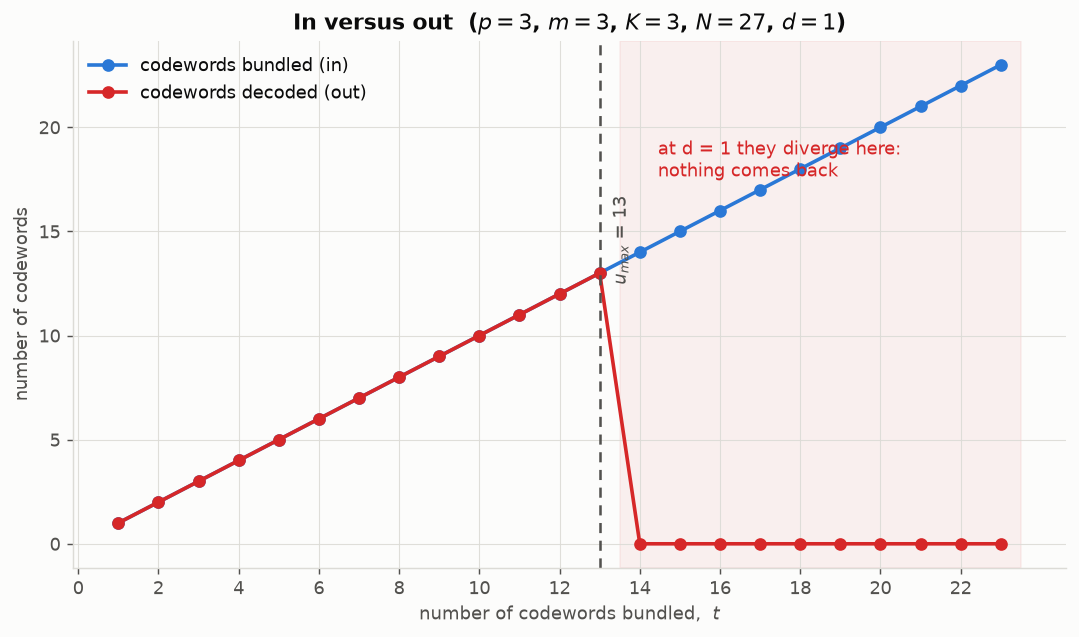

the two lines coincide for t = 1..13, then the red line drops to zero.
at d = 1 it is a cliff, not a slope: t = 13 returns all 13, t = 14 returns none.


In [14]:
mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "savefig.facecolor": "#fcfcfb", "text.color": "#0b0b0b",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.edgecolor": "#dcdbd6", "grid.color": "#dcdbd6",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.linewidth": 0.6, "grid.alpha": 0.9,
    "lines.linewidth": 2.0, "lines.markersize": 6,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 130, "savefig.dpi": 130,
})
import os
os.makedirs("figures", exist_ok=True)

ts = [r["t"] for r in rows]
rec = [r["n_rec"] for r in rows]

fig, ax = plt.subplots(figsize=(8.4, 5.0))
ax.plot(ts, ts, color="#2a78d6", marker="o", label="codewords bundled (in)")
ax.plot(ts, rec, color="#d62728", marker="o", label="codewords decoded (out)")
ax.axvline(U_MAX, color="#52514e", linestyle=(0, (4, 3)), linewidth=1.4)
ax.annotate(f"$u_{{max}}$ = {U_MAX}", (U_MAX, max(ts) * 0.55), xytext=(7, 0),
            textcoords="offset points", color="#52514e", fontsize=10, rotation=90)
split = U_MAX + 0.5
ax.axvspan(split, max(ts) + 0.5, color="#d62728", alpha=0.06)
ax.annotate("at d = 1 they diverge here:\nnothing comes back",
            (U_MAX + 1, max(ts) * 0.80), xytext=(10, 0), textcoords="offset points",
            color="#d62728", fontsize=10, va="center")
ax.set_xlabel("number of codewords bundled,  $t$")
ax.set_ylabel("number of codewords")
ax.set_xticks(range(0, max(ts) + 1, 2))
ax.set_title(f"In versus out  ($p={p}$, $m={m}$, $K={K}$, $N={N}$, $d=1$)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figures/hr_in_vs_out.png", bbox_inches="tight")
plt.show()

print(f"the two lines coincide for t = 1..{U_MAX}, then the red line drops to zero.")
print(f"at d = 1 it is a cliff, not a slope: t = {U_MAX} returns all {U_MAX}, "
      f"t = {U_MAX + 1} returns none.")

## Why it falls off exactly there (at $d = 1$)

Two arguments, from two different papers, that give the same number at $d = 1$ --- but mean different things.
All three source PDFs are in this repo (`ls *.pdf` --- they are gitignored).

### The score argument --- `histo.pdf`, Lemma 2 (p. 5)

> **Lemma 2.** For any Kautz--Singleton codeword $\bar W \notin \{W^{(i)}\}_{i=1}^{t}$, we
> have $|\mathrm{supp}(\bar W) \cap \mathrm{supp}(Y)| \le t(K-1)$.
>
> *Proof.* Since any two distinct Reed--Solomon codewords agree in at most $K-1$ entries...

A genuine codeword scores the maximum $N$ --- every symbol it has was observed. An
impostor can only collect accidental hits, and Lemma 2 caps those at $t(K-1)$. Note what
this bounds: *spurious* codewords. Past the bound an impostor *may* reach the maximum
score, but the genuine codewords still score $dN$ and still come out. The paper
draws the conclusion immediately after:

> by requiring that $dt(K-1) < dN$, we effectively guarantee that all spurious codewords
> yield an inner product with $M$ of strictly less than $dN$ ... the latter condition is
> equivalent to $t < \frac{N}{K-1}$

which is the second term of its **equation (6)**, $\left\lfloor\frac{N-1}{K-1}\right\rfloor$
--- the *strength* of the Kautz--Singleton code. `histo.pdf`'s **Example 2** (p. 5) proves
that ceiling cannot be beaten *as a worst-case guarantee*, by exhibiting two different
sets of 7 codewords over $\mathbb{F}_7$ with identical histograms. That shows *some*
bundle one past the ceiling is ambiguous, not that *every* one is.

### The degree argument --- Guruswami--Sudan, Lemma 4 (p. 4)

> **Lemma 4.** If $p(x)$ is a polynomial of degree at most $k$ such that $y_i = p(x_i)$ for
> at least $t$ values of $i \in [n]$ and $rt > l$, then $y - p(x)$ divides $Q$.

Careful with letters --- **their $t$ is the number of agreeing positions, not the number
of bundled codewords**. Translating into this notebook:

| Guruswami--Sudan | here | value |
|---|---|---|
| $r$ (multiplicity) | $d$ | 1 |
| $t$ (agreement) | $N$ --- a bundled codeword matches everywhere | 27 |
| $l$ (weighted-degree bound) | the interpolation budget | $Nd - 1$ |

So $rt > l$ reads $Nd > Nd - 1$: satisfied, and every bundled codeword is *forced* to
appear as a factor of $Q$. The weighted degree is the $(1, K-1)$ one that
Sidorenko--Fischer's **Algorithm 1, step 1** (p. 4) asks for:

> Compute a nontrivial bivariate polynomial $p(x,y)$ of **minimal $(1, k-1)$-weighted
> degree** that passes through each point $(x_i, y_i) \in P$ with multiplicity at least $m_i$

Now count. $Q$ must be divisible by all $t$ factors at once, each of degree $\le K-1$, so

$$\text{weighted degree of } Q \;\ge\; t\,(K-1)$$

against a budget of $Nd$. At $d = 1$ a curve exists only while $t(K-1) < N$ --- the same
inequality as the score argument, reached from degrees instead of scores. But the budget
grows with $d$: the $y$-degree cap is $\lfloor (Nd-1)/(K-1) \rfloor$, which is 13 at
$d = 1$, 26 at $d = 2$, and 53 at $d = 4$.

### Measured

The dimension of the space of valid curves:

| $t$ | $t(K-1)$ | budget $N$ | fits? | curves available |
|---|---|---|---|---|
| 11 | 22 | 27 | yes | 9 |
| 12 | 24 | 27 | yes | 4 |
| 13 | 26 | 27 | yes | **1** |
| 14 | 28 | 27 | **no** | **0** |

At $t = 13$ there is **exactly one** curve, and it is $\prod_{i=1}^{13}(y - f_i(x))$ ---
weighted degree 26, just inside 27, vanishing at all 285 observed points. The decoder is
squeezed down to the single polynomial whose factors *are* the answers. One more codeword
needs degree 28, nothing fits, and that is the cliff --- at $d = 1$.

Two footnotes on the bounds that do *not* fire here:

- Sidorenko--Fischer **Theorem 1, eq. (11)** --- $\langle WM\rangle \ge \sqrt{2(k-1)C(M)}$
  --- is only *sufficient*. With $d = 1$ it lapses around $t = 7$ and recovery continues
  to 13 regardless.
- `histo.pdf` **Theorem 1** guarantees recovery *as long as* $u$ is below both terms of
  **(6)**, $\frac{d}{d+1}\cdot\frac{N}{K-1}$ and $\frac{N-1}{K-1}$. That is sufficient,
  not necessary. It covers every possible bundle, including one with no collisions
  ($n_P = tN$). This bundle has collisions --- $n_P = 305$ at $t = 14$, not 378 --- and
  that slack is what Part 5 uses.

# Repeated codewords (§IV-B3)

Everything above bundles *distinct* codewords. If the same one goes in twice, something
has to give --- and the thing that gives is $Y$.

$Y$ records only **whether** a symbol appeared, not how often. So bundling $a, a, b$
produces the exact same $Y$ as bundling $a, b$, and the decoder cannot possibly
distinguish them. The paper says so plainly:

> duplicate codewords do not change any entries in $Y$ ... Kautz--Singleton decoding will
> return only the distinct codewords. To find their multiplicities, **subtract the
> histograms of these unique codewords from the histograms given as input, and run the
> decoding algorithm again. Keep repeating this process until the residual histograms
> become zero.**

The *counts* survive even though $Y$ loses them --- a cell holding 2 means two bundled
codewords share that symbol there. So peel one layer at a time:

1. decode the residual $\to$ the distinct codewords in it
2. subtract each one's histogram
3. repeat until the residual is all zero

This also explains why Theorem 1 bounds $u$ (distinct) rather than $t$ (total), and why
Remark 3 can say the total is unrestricted: each round removes at least one *distinct*
codeword, so the loop runs at most $u$ times no matter how large $t$ is.

In [15]:
def unbundle_with_multiplicities(hist, d=1):
    """Section IV-B3: recover the multiset, not just the set.

    Each round decodes the distinct codewords still present, subtracts their
    histograms, and repeats on what is left.
    """
    residual = hist.copy()
    multiset, rounds = [], []
    while residual.any():
        Y = (residual > 0).astype(int)
        found, _, _ = unbundle(Y, d=d)
        msgs = [message_of_poly(f) for f in found]
        rounds.append((int(residual.sum(axis=0)[0]), sorted(msgs)))
        for u in msgs:
            for j, sym in enumerate(enc["reed_solomon_encode"](u, p, m, tab)):
                residual[int(sym), j] -= 1        # subtract this codeword's histogram
            multiset.append(u)
        assert (residual >= 0).all(), "a residual count went negative"
    return multiset, rounds


A, B = MESSAGES[0], MESSAGES[1]
MULTISET = [A, A, B]                              # 'a' twice, 'b' once
print(f"bundling the multiset a, a, b = {MULTISET}\n")

s = sum(enc["histo_encode"](u, p, m, tab) for u in MULTISET)
h = histograms(s)
print(f"  column sums: all {h.sum(axis=0)[0]}  -> t = 3, the TOTAL with multiplicity")
print(f"  largest count in any cell: {h.max()}  <- a 2 marks where 'a' doubled up")

Y_aab = (h > 0).astype(int)
Y_ab = support_matrix(histograms(sum(enc["histo_encode"](u, p, m, tab) for u in [A, B])))
print(f"\n  Y for a,a,b is identical to Y for a,b: {np.array_equal(Y_aab, Y_ab)}")
print(f"  so one pass of the decoder can only ever return the DISTINCT ones.\n")

multiset, rounds = unbundle_with_multiplicities(h)
for i, (colsum, msgs) in enumerate(rounds, 1):
    print(f"  round {i}: residual holds {colsum} codeword(s); decoder returns "
          f"{len(msgs)} distinct {msgs}")
print(f"\n  residual now all zero -> stop after {len(rounds)} rounds")
print(f"  recovered multiset: {sorted(multiset)}")
assert sorted(multiset) == sorted(MULTISET)
print(f"  matches what went in: True")

# the loop length is bounded by the number of DISTINCT codewords, not the total
heavy = [A] * 20 + [B] * 7
h2 = histograms(sum(enc["histo_encode"](u, p, m, tab) for u in heavy))
ms2, rnds2 = unbundle_with_multiplicities(h2)
print(f"\n  stress: t = {len(heavy)} total but only {len({tuple(u) for u in heavy})} "
      f"distinct")
print(f"  -> finished in {len(rnds2)} rounds, recovered {len(ms2)} codewords, "
      f"correct: {sorted(ms2) == sorted(heavy)}")
print(f"  this is Remark 3: the TOTAL t is unrestricted, only the distinct count is "
      f"capped at u_max = {U_MAX}.")

bundling the multiset a, a, b = [[1, 1, 2], [1, 1, 2], [2, 3, 5]]

  column sums: all 3  -> t = 3, the TOTAL with multiplicity
  largest count in any cell: 2  <- a 2 marks where 'a' doubled up

  Y for a,a,b is identical to Y for a,b: True
  so one pass of the decoder can only ever return the DISTINCT ones.

  round 1: residual holds 3 codeword(s); decoder returns 2 distinct [[1, 1, 2], [2, 3, 5]]
  round 2: residual holds 1 codeword(s); decoder returns 1 distinct [[1, 1, 2]]

  residual now all zero -> stop after 2 rounds
  recovered multiset: [[1, 1, 2], [1, 1, 2], [2, 3, 5]]
  matches what went in: True



  stress: t = 27 total but only 2 distinct
  -> finished in 20 rounds, recovered 27 codewords, correct: True
  this is Remark 3: the TOTAL t is unrestricted, only the distinct count is capped at u_max = 13.


# Part 5 --- Past the bound: raise the multiplicity $d$

Part 3's wall came from the decoder, not the bundle. At $d = 1$, $Q$ has $y$-degree at most
13, so it cannot hold 14 roots. And because every bundled codeword matches $Y$ at all $N$
positions, Lemma 4 forces *all* of them to divide $Q$ --- so at $t = 14$ no $Q$ exists at
all, and nothing comes back, not even a subset.

Raising $d$ raises the budget to $Nd$ and the $y$-degree cap to $\lfloor (Nd-1)/(K-1)\rfloor$
while keeping Lemma 4 intact ($Nd > Nd - 1$). The price is constraints: each point now
imposes $d(d+1)/2$ of them. Counting unknowns against constraints gives a rough
Guruswami--Sudan list-recovery condition

$$n_P \;<\; \frac{d}{d+1}\cdot\frac{N^2}{K-1} \;\to\; \frac{N^2}{K-1} = 364.5$$

which collisions help with: at $t = 14$, $n_P = 305$. It is only a counting heuristic ---
the observed points are structured, so a curve can exist before the count says so.

`unbundle` from Part 3 retries every $\ell$ from 2 upward, which is fine at $d = 1$ but
wasteful here, so `unbundle_at` goes straight to the $y$-degree cap. Dense linear algebra
over $\mathbb{F}_{27}$ gets expensive fast: the $d = 4$ run below takes about five minutes.

In [16]:
def unbundle_at(Y, d):
    """Stage B at multiplicity d, with ell set straight to the y-degree cap.
    Returns (kept polynomials, matrix shape), or (None, shape) if no curve exists."""
    from sage.coding.guruswami_sudan.interpolation import _interpolation_matrix_problem
    P = [(points[j], points[a]) for j in range(N) for a in range(N) if Y[a, j]]
    tau, ell = len(P) - N, (N * d - 1) // (K - 1)
    shape = _interpolation_matrix_problem(P, tau, (d, ell), K - 1)[0].dimensions()
    try:
        Q = gs_interpolation_linalg(P, tau, (d, ell), K - 1)
    except IndexError:                     # empty kernel: no curve at this d
        return None, shape
    kept = [f for f in ROOT_FINDER(Q, maxd=K - 1)
            if score([FROM_SAGE[f(x)] for x in points], d * Y) >= d * N]
    return kept, shape


t = U_MAX + 1
Y = support_matrix(histograms(BUNDLES[t - 1]))
n_P = int(Y.sum())
want = sorted(MESSAGES[:t])
print(f"t = {t}, one past u_max = {U_MAX}.   n_P = {n_P},  (K-1) n_P = {(K - 1) * n_P}"
      f"  vs  N^2 = {N * N}\n")
print(f"   {'d':>3} {'y-cap':>6} {'matrix':>12} {'recovered':>10} {'spurious':>9} {'exact?':>7} {'s':>6}")
D_ROWS = []
for d in (1, 2, 3, 4):
    t0 = time.time()
    found, (nr, nc) = unbundle_at(Y, d)
    secs = time.time() - t0
    got = [] if found is None else [message_of_poly(f) for f in found]
    hit = sum(1 for u in got if u in want)
    exact = sorted(got) == want
    D_ROWS.append(dict(d=d, hit=hit, exact=exact))
    print(f"   {d:>3} {(N * d - 1) // (K - 1):>6} {f'{nr}x{nc}':>12} {hit:>10} "
          f"{len(got) - hit:>9} {str(exact):>7} {secs:>6.0f}")
    if exact:
        break

assert D_ROWS[-1]["exact"], "expected some d <= 4 to recover t = u_max + 1"
print(f"\n   d = {D_ROWS[-1]['d']} recovers all {t} bundled codewords, nothing spurious.")
print(f"   u_max = {U_MAX} is the paper's worst-case guarantee; this bundle, with its")
print(f"   collisions, decodes past it. The d = 1 wall in Part 3 was the decoder's.")


t = 14, one past u_max = 13.   n_P = 305,  (K-1) n_P = 610  vs  N^2 = 729

     d  y-cap       matrix  recovered  spurious  exact?      s


     1     13      305x196          0         0   False      0


     2     26      915x756          0         0   False      8


     3     40    1830x1681          0         0   False     55


     4     53    3050x2970         14         0    True    290

   d = 4 recovers all 14 bundled codewords, nothing spurious.
   u_max = 13 is the paper's worst-case guarantee; this bundle, with its
   collisions, decodes past it. The d = 1 wall in Part 3 was the decoder's.
